# Étape 4 — Analyse exploratoire
Toutes les conclusions ci-dessous sont calculées à partir des fichiers du projet. Le 2011-12-09, jour partiel, est exclu.

In [1]:
import sys
import pandas as pd
import numpy as np
import statsmodels
import matplotlib
print('sys.executable:', sys.executable)
print('sys.version:', sys.version)
print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('statsmodels:', statsmodels.__version__)
print('matplotlib:', matplotlib.__version__)

sys.executable: C:\Users\Admin\Desktop\retail-revenue-forecasting\.venv\Scripts\python.exe
sys.version: 3.12.8 (tags/v3.12.8:2dc476b, Dec  3 2024, 19:30:04) [MSC v.1942 64 bit (AMD64)]
pandas: 3.0.6
numpy: 2.5.4
statsmodels: 0.15.0
matplotlib: 3.11.2


In [2]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from retail_forecast.data.eda import (eda_summary, weekday_profile, decompose_weekly, anomaly_details, cleaning_impact, cleaning_impact_steps)
from retail_forecast.data.load import load_config
config = load_config(ROOT / 'configs' / 'config.yaml')
clean = pd.read_csv(ROOT / 'data/interim/clean_transactions.csv', dtype={'InvoiceNo':'string','StockCode':'string','CustomerID':'string'}, parse_dates=['InvoiceDate'])
raw = pd.read_csv(ROOT / 'data/raw/online_retail.csv', dtype={'InvoiceNo':'string','StockCode':'string','CustomerID':'string'}, parse_dates=['InvoiceDate'])
daily = pd.read_csv(ROOT / 'data/processed/daily_revenue.csv', parse_dates=['date'])
weekly = pd.read_csv(ROOT / 'data/processed/weekly_revenue.csv', parse_dates=['date'])
anomalous = pd.read_csv(ROOT / 'data/processed/anomalous_days.csv', parse_dates=['date'])
transaction_counts = clean.assign(date=clean.InvoiceDate.dt.normalize()).groupby('date').size()
daily['n_transactions'] = daily.date.map(transaction_counts).fillna(0).astype(int)
summary = eda_summary(clean, daily)
profile = weekday_profile(daily)
impact = cleaning_impact(raw, clean)
cleaning_steps = cleaning_impact_steps(raw, pd.read_csv(ROOT / 'data/interim/cleaning_summary.csv'), config)
details = anomaly_details(clean, anomalous)
figures = ROOT / 'reports/figures'; figures.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')

## a. Contexte et chaîne de nettoyage

In [3]:
cleaning_summary = pd.read_csv(ROOT / 'data/interim/cleaning_summary.csv')
display(cleaning_summary)
display(impact)
display(cleaning_steps)
print(f"Le nettoyage conserve {len(clean):,} lignes sur {len(raw):,}, soit {len(clean)/len(raw):.1%}, et le revenu nettoyé vaut £{clean.Revenue.sum():,.2f}.")

,step,rows_before,rows_after,removed,note
0,drop_exact_duplicates,541909,536641,5268,NaN
1,flag_cancellations,536641,536641,0,NaN
2,drop_cancelled_orders,536641,533763,2878,NaN
3,exclude_cancellations,533763,524512,9251,NaN
4,remove_invalid_prices,524512,522000,2512,NaN
5,remove_non_product_codes,522000,519726,2274,NaN
6,remove_non_product_invoices,519726,519726,0,NaN
7,remove_invalid_quantities,519726,519726,0,NaN
8,winsorize,519726,519726,0,0 plafonnements
9,add_revenue,519726,519726,0,0 ligne supprimée


,dataset,rows,revenue
0,raw,541909,9.747748e+06
1,raw_without_cancellations,532621,1.064456e+07
2,clean,519726,9.821479e+06


,step,rows_removed,revenue_removed
0,drop_exact_duplicates,5268,21740.980
1,flag_cancellations,0,0.000
2,drop_cancelled_orders,2878,444831.780
3,exclude_cancellations,9251,-893979.730
4,remove_invalid_prices,2512,-22124.120
5,remove_non_product_codes,2274,375799.811
6,remove_non_product_invoices,0,0.000
7,remove_invalid_quantities,0,0.000
8,winsorize,0,0.000
9,add_revenue,0,0.000


Le nettoyage conserve 519,726 lignes sur 541,909, soit 95.9%, et le revenu nettoyé vaut £9,821,479.21.


### Conclusion — nettoyage

Le nettoyage conserve **519 726 lignes sur 541 909**, soit **95,9 %**, pour un revenu nettoyé calculé de **£9 821 479,21**. Les annulations et codes non-produits sont donc traités avant toute modélisation.

## b. Revenu journalier et hebdomadaire

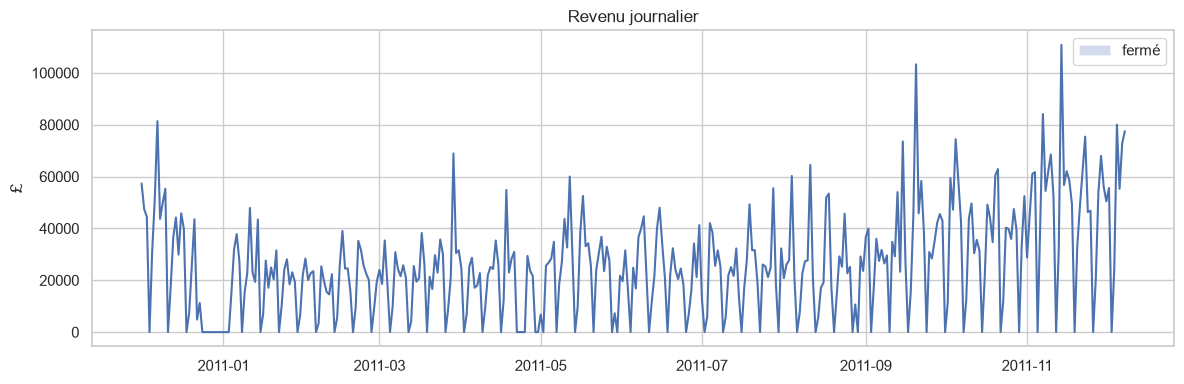

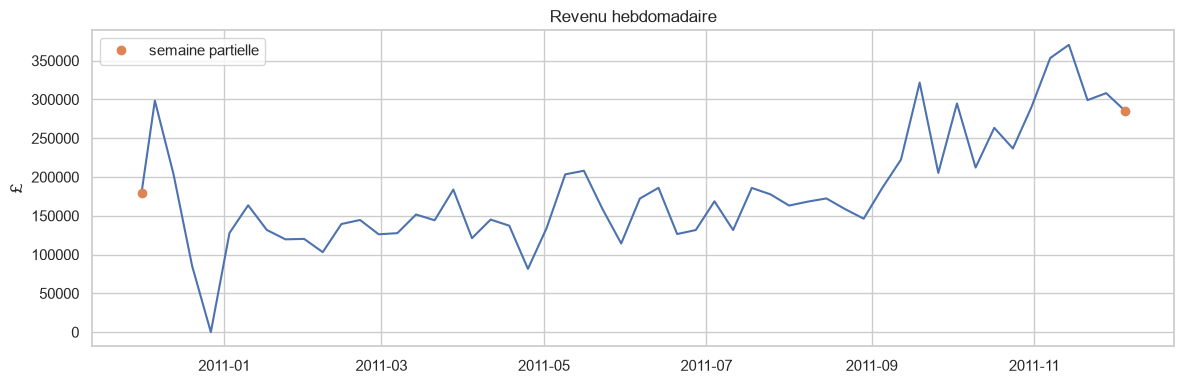

Série: 2010-12-01 à 2011-12-08, 373 jours.
IDXMAX: date=2011-11-14, revenue=£110,815.68
TOP5_DAYS:
      date   revenue
2011-11-14 110815.68
2011-09-20 103293.08
2011-11-07  84108.61
2010-12-07  81368.44
2011-12-05  80011.23
MONTHLY_ACTIVE_MEANS_COMPLETE=
                 mean  n_days
month                        
2011-01  23530.538750      24
2011-02  21030.000417      24
2011-03  25270.172593      27
2011-04  24264.032905      21
2011-05  29305.501600      25
2011-06  26539.324231      26
2011-07  26250.858115      26
2011-08  27506.607308      26
2011-09  39140.043885      26
2011-10  41190.790385      26
2011-11  55340.449231      26
TENDANCE_JAN_OCT: janvier=£23,530.54, octobre=£41,190.79, variation=£17,660.25 (75.05%); pente linéaire janvier-octobre=£73.63/jour. Avec un seul cycle annuel, la tendance de fond n'est pas identifiable de façon fiable.


In [4]:
fig, ax = plt.subplots(figsize=(12, 4)); ax.plot(daily.date, daily.revenue)
ax.fill_between(daily.date, 0, daily.revenue, where=~daily.is_trading_day, alpha=.25, label='fermé')
ax.set(title='Revenu journalier', ylabel='£'); ax.legend(); fig.tight_layout(); fig.savefig(figures/'daily_revenue.png'); plt.show()
fig, ax = plt.subplots(figsize=(12, 4)); ax.plot(weekly.date, weekly.revenue)
partial = weekly.loc[weekly.is_partial_week]; ax.plot(partial.date, partial.revenue, linestyle='None', marker='o', label='semaine partielle')
ax.set(title='Revenu hebdomadaire', ylabel='£'); ax.legend(); fig.tight_layout(); fig.savefig(figures/'weekly_revenue.png'); plt.show()
max_day = daily.loc[daily.revenue.idxmax()]
top5_days = daily.nlargest(5, 'revenue')[['date', 'revenue']]
active_eda = daily.loc[daily.is_trading_day & ~daily.date.between('2010-12-24', '2011-01-03')].copy()
active_eda['month'] = active_eda.date.dt.to_period('M').astype(str)
complete_months = active_eda.loc[active_eda.month.between('2011-01', '2011-11')].copy()
monthly_stats = complete_months.groupby('month').agg(total=('revenue', 'sum'), mean=('revenue', 'mean'), n_days=('date', 'size'))
nov_stats = monthly_stats.loc['2011-11']
nov_total_rank = int(monthly_stats.total.rank(ascending=False, method='min').loc['2011-11'])
nov_mean_rank = int(monthly_stats['mean'].rank(ascending=False, method='min').loc['2011-11'])
nov_total_ratio = nov_stats.total / monthly_stats.total.median()
nov_mean_ratio = nov_stats['mean'] / monthly_stats['mean'].median()
jan_mean = monthly_stats.loc['2011-01', 'mean']; oct_mean = monthly_stats.loc['2011-10', 'mean']
jan_oct = complete_months.loc[complete_months.month.between('2011-01', '2011-10')]
trend_slope = float(__import__('numpy').polyfit(range(len(jan_oct)), jan_oct.revenue.to_numpy(float), 1)[0])
print(f"Série: {daily.date.min().date()} à {daily.date.max().date()}, {len(daily)} jours.")
print(f"IDXMAX: date={max_day.date.date()}, revenue=£{max_day.revenue:,.2f}")
print('TOP5_DAYS:'); print(top5_days.to_string(index=False))
print('MONTHLY_ACTIVE_MEANS_COMPLETE='); print(monthly_stats[['mean', 'n_days']].to_string())
print(f"TENDANCE_JAN_OCT: janvier=£{jan_mean:,.2f}, octobre=£{oct_mean:,.2f}, variation=£{oct_mean-jan_mean:,.2f} ({oct_mean/jan_mean-1:.2%}); pente linéaire janvier-octobre=£{trend_slope:,.2f}/jour. Avec un seul cycle annuel, la tendance de fond n'est pas identifiable de façon fiable.")

### Conclusion — tendance

Le maximum calculé par `daily.revenue.idxmax()` est **£110 815,68 le 2011-11-14**. Sur les mois complets de janvier à novembre 2011, la moyenne par jour actif passe de **£23 530,54 en janvier** à **£41 190,79 en octobre**, soit **+75,05 %** hors novembre ; la pente janvier-octobre est de **£73,63/jour**. Avec un seul cycle annuel, la tendance de fond n'est pas identifiable de façon fiable.

### Conclusion — fermeture observée

La fenêtre du **24 décembre 2010 au 3 janvier 2011** contient **0 transaction** et **£0,00** de revenu dans les données. Pour Noël 2011, cette fermeture est une hypothèse de calendrier affichée, car un seul Noël est observé.

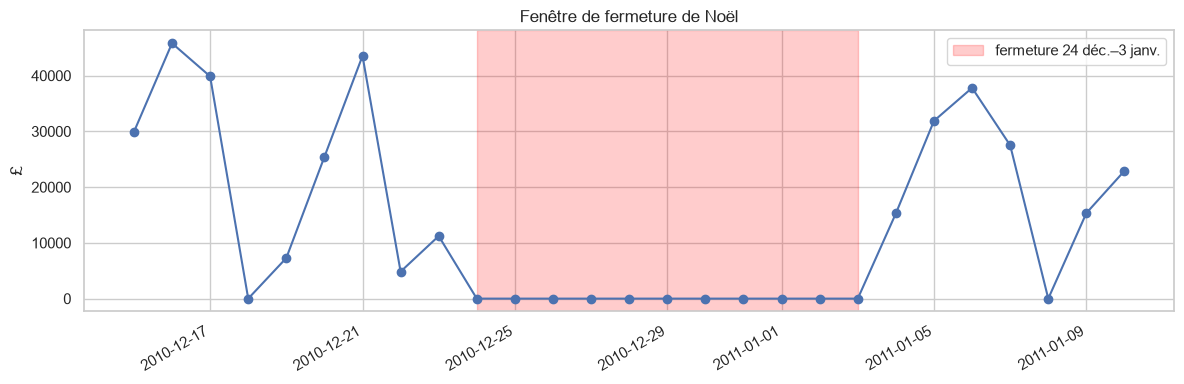

Fenêtre 2010-12-15 → 2011-01-10 : 27 jours, 20122 transactions dans la fermeture, £0.00 sur la fermeture.


In [5]:
closure_window = daily.loc[daily.date.between('2010-12-15', '2011-01-10')]
fig, ax = plt.subplots(figsize=(12, 4)); ax.plot(closure_window.date, closure_window.revenue, marker='o')
ax.axvspan(pd.Timestamp('2010-12-24'), pd.Timestamp('2011-01-03'), alpha=.2, color='red', label='fermeture 24 déc.–3 janv.')
ax.set(title='Fenêtre de fermeture de Noël', ylabel='£'); ax.legend(); fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(figures/'christmas_closure_window.png'); plt.show()
print(f"Fenêtre 2010-12-15 → 2011-01-10 : {len(closure_window)} jours, {int(closure_window.n_transactions.sum())} transactions dans la fermeture, £{closure_window.loc[closure_window.date.between('2010-12-24','2011-01-03'),'revenue'].sum():,.2f} sur la fermeture.")

## c. Profil par jour de semaine

,weekday,mean,median,n_days
0,Friday,30660.704306,26327.730,49
1,Monday,35399.452979,28397.560,47
2,Sunday,15815.592220,12161.890,50
3,Thursday,39622.375472,35596.740,53
4,Tuesday,37889.883288,32955.605,52
5,Wednesday,33295.583585,27774.660,53


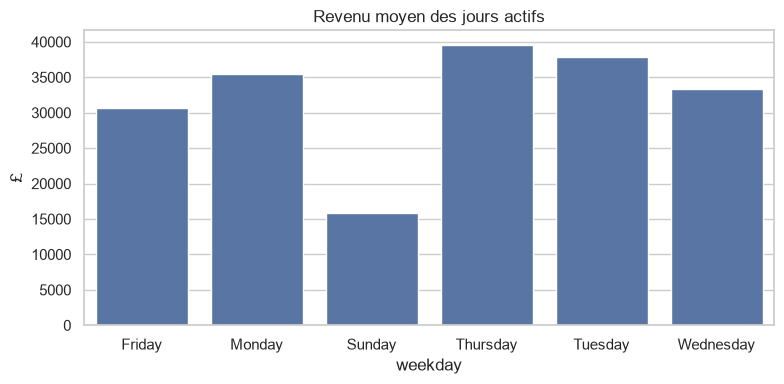

Le samedi compte 53 jours dans la série et 0.00 £ de revenu.


In [6]:
display(profile)
fig, ax = plt.subplots(figsize=(8, 4)); sns.barplot(profile, x='weekday', y='mean', ax=ax)
ax.set(title='Revenu moyen des jours actifs', ylabel='£'); fig.tight_layout(); fig.savefig(figures/'weekday_profile.png'); plt.show()
print(f"Le samedi compte {int((daily.date.dt.dayofweek==5).sum())} jours dans la série et {int(daily.loc[daily.date.dt.dayofweek==5, "revenue"].sum()):,.2f} £ de revenu.")

### Conclusion — saisonnalité hebdomadaire

Le profil calculé couvre **6 jours actifs** : lundi à vendredi et dimanche. Le samedi est structurellement fermé dans la série et doit être modélisé par la variable `is_trading_day`, non comme une absence aléatoire.

## d. Saisonnalité mensuelle

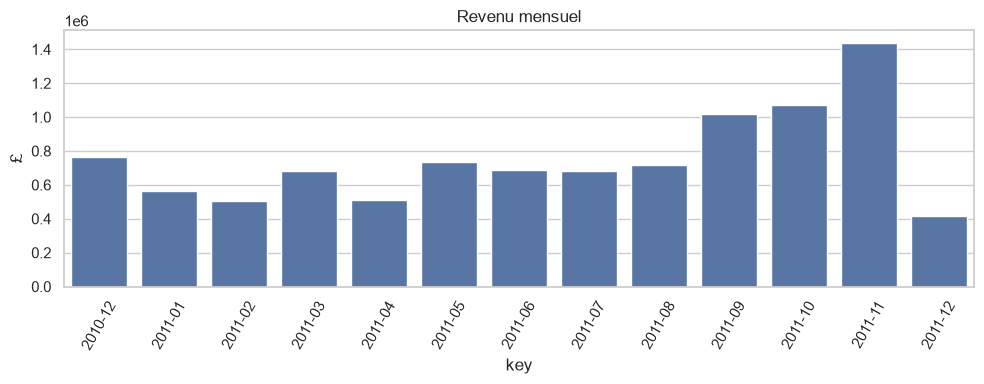

NOVEMBER_TOTAL: £1,438,851.68; rang=1/11, ratio_mois_median=2.09x.
NOVEMBER_ACTIVE_DAILY_MEAN: £55,340.45; rang=1/11, ratio_moyenne_mensuelle_mediane=2.09x; jours actifs=26.
DECEMBER_2010: décembre 2010 est affecté par la fermeture du 24 au 31, soit 20 jours actifs observés; exclu du rang.
DECEMBER_PARTIAL: décembre 2011 est partiel, jusqu'au 2011-12-08, soit 7 jours actifs observés; exclu du rang.
CLOSURE: 0 transactions et £0.00 du 24 décembre au 3 janvier.


In [7]:
monthly = summary.query("dimension == 'month'")
fig, ax = plt.subplots(figsize=(10, 4)); sns.barplot(monthly, x='key', y='revenue', ax=ax); ax.tick_params(axis='x', rotation=60)
ax.set(title='Revenu mensuel', ylabel='£'); fig.tight_layout(); fig.savefig(figures/'monthly_revenue.png'); plt.show()
nov = monthly.loc[monthly.key.eq('2011-11'), 'revenue'].iloc[0]
print(f"NOVEMBER_TOTAL: £{nov:,.2f}; rang={nov_total_rank}/{len(monthly_stats)}, ratio_mois_median={nov_total_ratio:.2f}x.")
print(f"NOVEMBER_ACTIVE_DAILY_MEAN: £{nov_stats['mean']:,.2f}; rang={nov_mean_rank}/{len(monthly_stats)}, ratio_moyenne_mensuelle_mediane={nov_mean_ratio:.2f}x; jours actifs={int(nov_stats['n_days'])}.")
observed_monthly = active_eda.groupby('month').agg(n_days=('date', 'size'))
print(f"DECEMBER_2010: décembre 2010 est affecté par la fermeture du 24 au 31, soit {int(observed_monthly.loc['2010-12', 'n_days'])} jours actifs observés; exclu du rang.")
print(f"DECEMBER_PARTIAL: décembre 2011 est partiel, jusqu'au {daily.date.max().date()}, soit {int(observed_monthly.loc['2011-12','n_days'])} jours actifs observés; exclu du rang.")
print(f"CLOSURE: {int(daily.loc[daily.date.between('2010-12-24','2011-01-03'),'n_transactions'].sum())} transactions et £{daily.loc[daily.date.between('2010-12-24','2011-01-03'),'revenue'].sum():,.2f} du 24 décembre au 3 janvier.")

### Conclusion — saisonnalité mensuelle

Sur les **11 mois complets de janvier à novembre 2011**, novembre est premier en revenu total (**£1 438 851,68**, ratio **2,09×** la médiane) et premier en moyenne par jour actif (**£55 340,45**, ratio **2,09×**). Décembre 2010 est affecté par la fermeture du 24 au 31 et décembre 2011 est partiel jusqu'au 8 : ces deux mois sont exclus du rang.

## e. Décomposition hebdomadaire

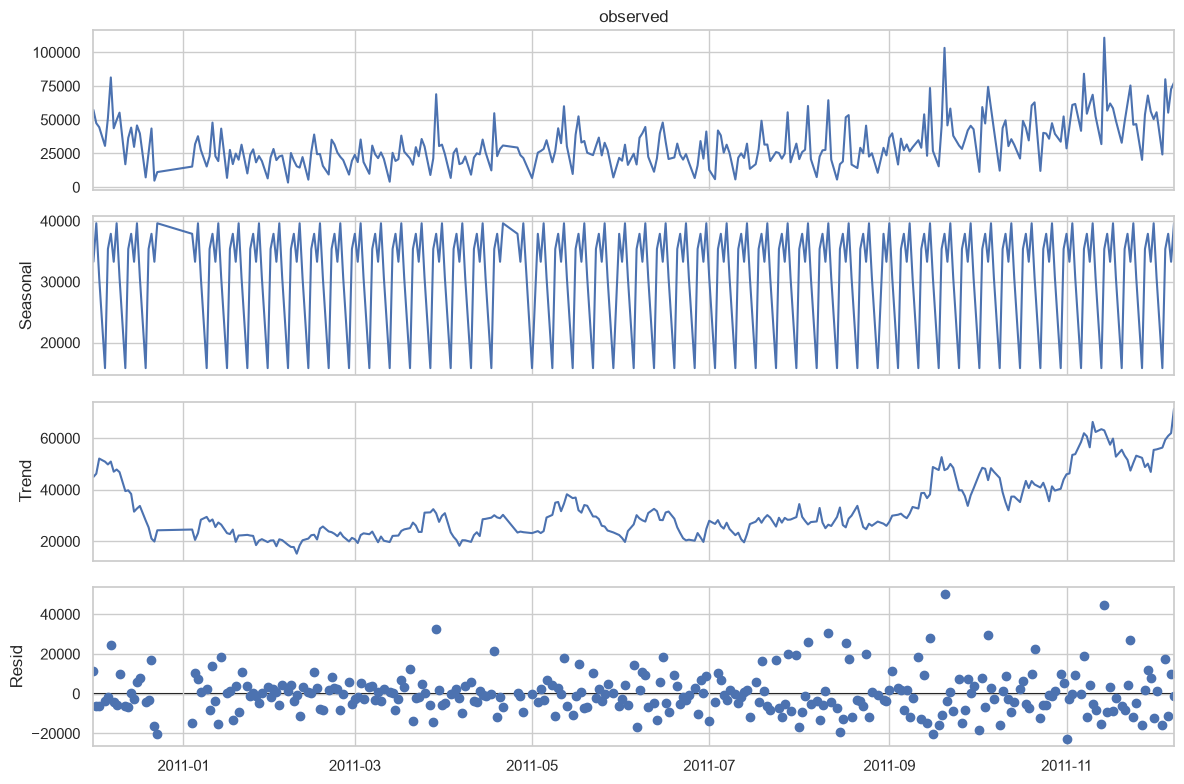

DECOMPOSITION_DAYS: 304 jours après exclusion des jours fermés et de la fenêtre 24 décembre–3 janvier.
Méthode: jours fermés et la fenêtre 24 décembre–3 janvier retirés; saisonnalité = moyenne par jour de semaine et résidu = écart après tendance roulante de 7 observations actives.


In [8]:
decomp = decompose_weekly(daily)
fig = decomp.plot(); fig.set_size_inches(12, 8); fig.tight_layout(); fig.savefig(figures/'decomposition.png'); plt.show()
print(f"DECOMPOSITION_DAYS: {len(decomp.observed)} jours après exclusion des jours fermés et de la fenêtre 24 décembre–3 janvier.")
print('Méthode: jours fermés et la fenêtre 24 décembre–3 janvier retirés; saisonnalité = moyenne par jour de semaine et résidu = écart après tendance roulante de 7 observations actives.')

### Conclusion — décomposition

La décomposition utilise une période hebdomadaire de **7 jours** et porte sur exactement **304 jours actifs** après exclusion des jours fermés et de la fenêtre du 24 décembre au 3 janvier. Seule la composante hebdomadaire est interprétable de façon robuste ; l’annualité est limitée par le seul Noël observé.

## f. Jours anormaux

,date,rank,InvoiceNo,StockCode,CustomerID,Quantity,UnitPrice,Revenue,share_of_day
0,2011-03-29,1,548203,22197,<NA>,637,1.95,1242.15,0.018023
1,2011-03-29,2,548011,22629,14646.0,640,1.65,1056.00,0.015322
2,2011-03-29,3,548011,22630,14646.0,640,1.65,1056.00,0.015322
3,2011-08-04,1,562439,84879,12931.0,2880,1.45,4176.00,0.069340
4,2011-08-04,2,562439,22191,12931.0,348,7.65,2662.20,0.044205
5,2011-08-04,3,562439,22197,12931.0,1900,0.72,1368.00,0.022715
6,2011-08-11,1,563074,84879,12931.0,968,1.45,1403.60,0.021766
7,2011-08-11,2,563074,22992,12931.0,432,1.65,712.80,0.011054
8,2011-08-11,3,563074,22991,12931.0,432,1.65,712.80,0.011054
9,2011-08-17,1,563590,23243,17450.0,352,5.15,1812.80,0.034973


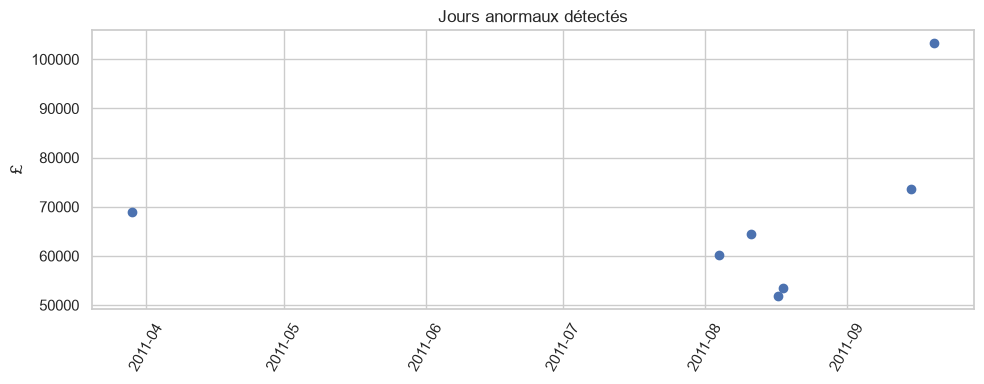

2011-03-29: top 3 = £3,354.15, part = 4.9%; conclusion: contribution des trois plus grosses lignes à examiner avant de qualifier le jour de pic réel.
2011-08-04: top 3 = £8,206.20, part = 13.6%; conclusion: contribution des trois plus grosses lignes à examiner avant de qualifier le jour de pic réel.
2011-08-11: top 3 = £2,829.20, part = 4.4%; conclusion: contribution des trois plus grosses lignes à examiner avant de qualifier le jour de pic réel.
2011-08-17: top 3 = £4,220.00, part = 8.1%; conclusion: contribution des trois plus grosses lignes à examiner avant de qualifier le jour de pic réel.
2011-08-18: top 3 = £3,150.76, part = 5.9%; conclusion: contribution des trois plus grosses lignes à examiner avant de qualifier le jour de pic réel.
2011-09-15: top 3 = £7,328.00, part = 10.0%; conclusion: contribution des trois plus grosses lignes à examiner avant de qualifier le jour de pic réel.
2011-09-20: top 3 = £13,935.88, part = 13.5%; conclusion: contribution des trois plus grosses lign

,CustomerID,revenue,customer_key,share_of_day
0,17450.0,66818.18,17450,0.646880
1,14866.0,5460.96,14866,0.052869
2,<NA>,5084.01,<NA>,0.049219
3,13767.0,2250.90,13767,0.021791
4,15341.0,2020.52,15341,0.019561


CustomerID 17450 représente 64.69% du revenu du 2011-09-20.


In [9]:
display(details)
fig, ax = plt.subplots(figsize=(10, 4)); ax.scatter(anomalous.date, anomalous.revenue); ax.tick_params(axis='x', rotation=60)
ax.set(title='Jours anormaux détectés', ylabel='£'); fig.tight_layout(); fig.savefig(figures/'anomalies.png'); plt.show()
for date, group in details.groupby('date'):
    print(f"{date.date()}: top 3 = £{group.Revenue.sum():,.2f}, part = {group.share_of_day.sum():.1%}; conclusion: contribution des trois plus grosses lignes à examiner avant de qualifier le jour de pic réel.")
day_0920 = clean.loc[clean.InvoiceDate.dt.normalize().eq(pd.Timestamp('2011-09-20'))].copy()
customer_0920 = day_0920.groupby('CustomerID', dropna=False)['Revenue'].sum().sort_values(ascending=False).head(5).rename('revenue').reset_index()
customer_0920['customer_key'] = customer_0920.CustomerID.astype('string').str.replace(r'\.0$', '', regex=True)
customer_0920['share_of_day'] = customer_0920.revenue / day_0920.Revenue.sum()
display(customer_0920)
share_17450 = customer_0920.loc[customer_0920.customer_key.eq('17450'), 'share_of_day'].iloc[0]
print(f"CustomerID 17450 représente {share_17450:.2%} du revenu du 2011-09-20.")

### Conclusion — anomalies

Les **7 jours anormaux** représentent **£475 740,25**, soit **4,86 %** du revenu journalier total. Le 2011-09-20 est inclus et doit être signalé comme événement non prévisible : le client **17450 représente 64,69 %** du revenu de cette journée.

,scope,mean,median,std,share_total
0,avec_7_anomalies,26251.619767,24850.56,19998.524220,1.000000
1,sans_7_anomalies,25453.863178,24525.65,19199.241292,0.951415


ANOMALY_DATES: 2011-03-29, 2011-08-04, 2011-08-11, 2011-08-17, 2011-08-18, 2011-09-15, 2011-09-20


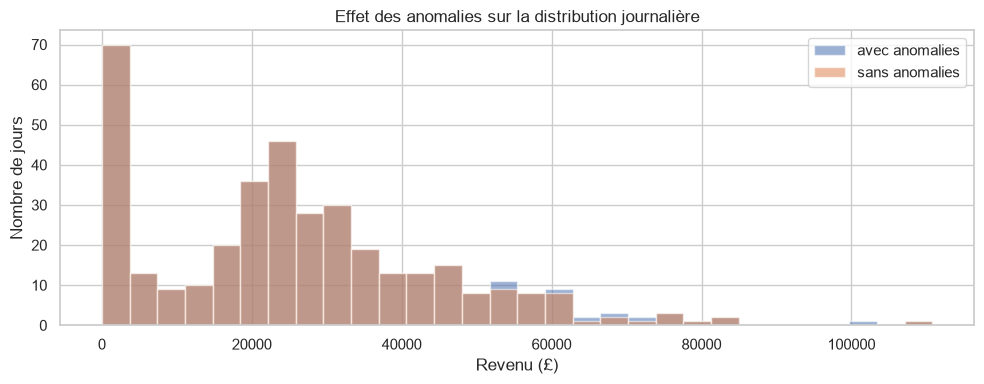

Avec anomalies : moyenne £26,251.62, médiane £24,850.56, écart-type £19,998.52, part 100.00%.
Sans anomalies : moyenne £25,453.86, médiane £24,525.65, écart-type £19,199.24, part 95.14%.
ANOMALY_RELATIVE_DROP: moyenne=3.04%, écart-type=4.00%; conclusion: les anomalies expliquent peu de la variance si la baisse de l'écart-type reste faible.


In [10]:
anomaly_dates = set(anomalous.date)
with_anomalies = daily.revenue
without_anomalies = daily.loc[~daily.date.isin(anomaly_dates), 'revenue']
anomaly_effect = pd.DataFrame([
    {'scope': 'avec_7_anomalies', 'mean': with_anomalies.mean(), 'median': with_anomalies.median(), 'std': with_anomalies.std(), 'share_total': with_anomalies.sum() / daily.revenue.sum()},
    {'scope': 'sans_7_anomalies', 'mean': without_anomalies.mean(), 'median': without_anomalies.median(), 'std': without_anomalies.std(), 'share_total': without_anomalies.sum() / daily.revenue.sum()},
])
display(anomaly_effect)
print('ANOMALY_DATES:', ', '.join(anomalous.date.dt.strftime('%Y-%m-%d')))
fig, ax = plt.subplots(figsize=(10, 4)); ax.hist(with_anomalies, bins=30, alpha=.55, label='avec anomalies'); ax.hist(without_anomalies, bins=30, alpha=.55, label='sans anomalies'); ax.set(title='Effet des anomalies sur la distribution journalière', xlabel='Revenu (£)', ylabel='Nombre de jours'); ax.legend(); fig.tight_layout(); fig.savefig(figures/'anomaly_effect.png'); plt.show()
print(f"Avec anomalies : moyenne £{with_anomalies.mean():,.2f}, médiane £{with_anomalies.median():,.2f}, écart-type £{with_anomalies.std():,.2f}, part {with_anomalies.sum()/daily.revenue.sum():.2%}.")
print(f"Sans anomalies : moyenne £{without_anomalies.mean():,.2f}, médiane £{without_anomalies.median():,.2f}, écart-type £{without_anomalies.std():,.2f}, part {without_anomalies.sum()/daily.revenue.sum():.2%}.")
mean_drop = 1 - without_anomalies.mean()/with_anomalies.mean()
std_drop = 1 - without_anomalies.std()/with_anomalies.std()
print(f"ANOMALY_RELATIVE_DROP: moyenne={mean_drop:.2%}, écart-type={std_drop:.2%}; conclusion: les anomalies expliquent peu de la variance si la baisse de l'écart-type reste faible.")

## g. Pays et produits

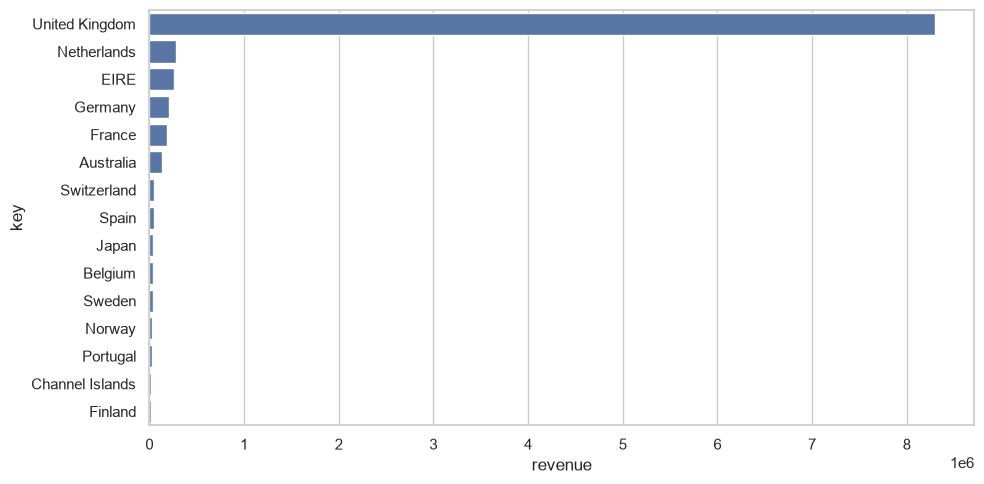

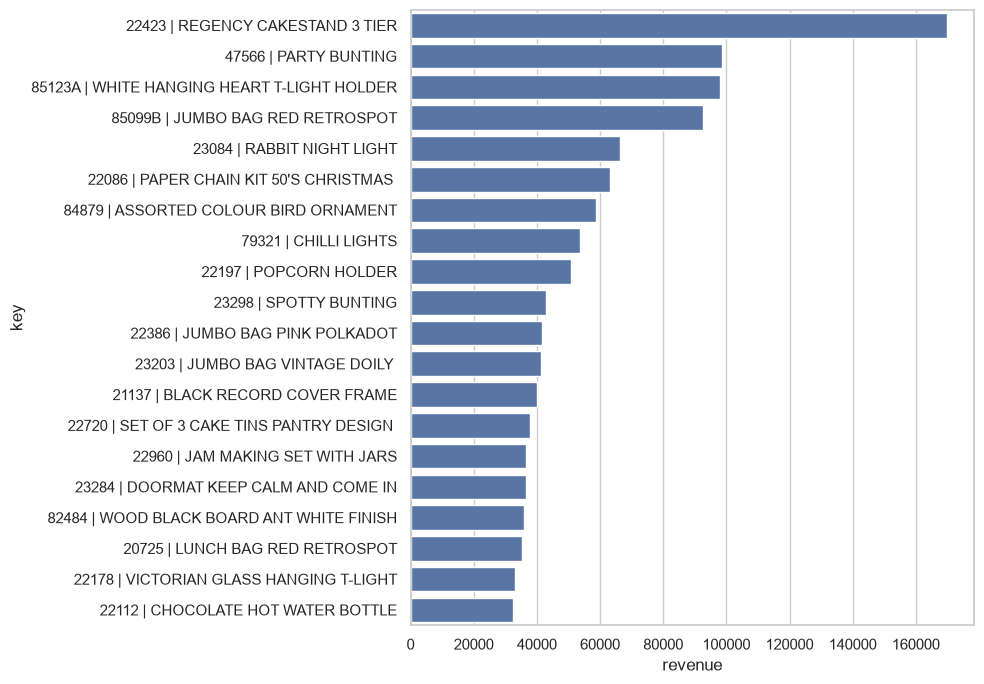

Le Royaume-Uni représente 84.5% du revenu nettoyé parmi les pays résumés.


In [11]:
country = summary.query("dimension == 'country'").sort_values('revenue', ascending=False).head(15)
products = summary.query("dimension == 'product'").head(20)
fig, ax = plt.subplots(figsize=(10, 5)); sns.barplot(country, y='key', x='revenue', ax=ax); fig.tight_layout(); fig.savefig(figures/'country.png'); plt.show()
fig, ax = plt.subplots(figsize=(10, 7)); sns.barplot(products, y='key', x='revenue', ax=ax); fig.tight_layout(); fig.savefig(figures/'products.png'); plt.show()
uk = country.loc[country.key.eq('United Kingdom'), 'revenue'].iloc[0]
print(f"Le Royaume-Uni représente {uk/clean.Revenue.sum():.1%} du revenu nettoyé parmi les pays résumés.")

### Conclusion — concentration géographique

Le Royaume-Uni représente **84,46 %** du revenu nettoyé calculé. La concentration géographique est donc forte ; les autres pays doivent être suivis comme segments minoritaires plutôt que mélangés sans contrôle.

## h. Synthèse et implications

In [12]:
print(f"1. {len(clean):,} transactions nettoyées produisent £{clean.Revenue.sum():,.2f}.")
print(f"2. La série comporte {len(daily)} jours et {int((~daily.is_trading_day).sum())} jours non actifs.")
print(f"3. Le pic journalier atteint £{daily.revenue.max():,.2f} le {daily.loc[daily.revenue.idxmax(), "date"].date()}.")
print(f"4. Novembre totalise £{nov:,.2f}; un seul Noël est observé, donc la saisonnalité de fin d’année est fragile.")
print(f"5. Les {len(anomalous)} jours anormaux doivent être conservés comme événements candidats, pas supprimés automatiquement.")
print(f"6. La série contient {int((daily.n_transactions==0).sum())} jours sans transaction; les jours fermés doivent être traités explicitement dans les features.")
print('Implications: le modèle devra intégrer les fermetures, le pic de novembre et l’incertitude liée à un seul cycle de Noël; la cible reste le revenu total.')

1. 519,726 transactions nettoyées produisent £9,821,479.21.
2. La série comporte 373 jours et 69 jours non actifs.
3. Le pic journalier atteint £110,815.68 le 2011-11-14.
4. Novembre totalise £1,438,851.68; un seul Noël est observé, donc la saisonnalité de fin d’année est fragile.
5. Les 7 jours anormaux doivent être conservés comme événements candidats, pas supprimés automatiquement.
6. La série contient 69 jours sans transaction; les jours fermés doivent être traités explicitement dans les features.
Implications: le modèle devra intégrer les fermetures, le pic de novembre et l’incertitude liée à un seul cycle de Noël; la cible reste le revenu total.


### Conclusion — synthèse

Les résultats calculés combinent **304 jours décomposés**, **69 jours non actifs**, un maximum journalier de **£110 815,68 le 2011-11-14**, une hausse de **75,05 % entre janvier et octobre** sur les moyennes journalières actives, **7 anomalies** et une concentration UK de **84,46 %**. Avec un seul cycle annuel, la tendance de fond reste incertaine ; les features doivent représenter les fermetures et les événements sans supprimer les observations.